# DBTT simulator: build and visualise a dataset

Simulates Charpy impact tests for a material whose energy-absorbed response follows an
**asymmetric hyperbolic tangent (AHT)**:

$$Y(T) = \frac{LS + US}{2} + \frac{US - LS}{2}\,\tanh\!\left(\frac{T - \mathrm{DBTT}}{C(T)}\right)$$

with $C(T) = C_\mathrm{lower}$ below the DBTT and $C_\mathrm{upper}$ above it.
Measurement noise is heteroscedastic: $\sigma(T) = \sigma_\mathrm{base} + \sigma_\mathrm{rel}\,Y(T)$.

The simulator follows the uncertainty-engine `Simulator` API: a config-driven leaf
implementing the raw forward map `_forward(X)`, with the public verb `simulate(X)`
returning a `SimulationResult`.

This notebook is the human-in-the-loop stand-in for the real experiment: you pick test
temperatures, the simulator returns energies, and you accumulate them in a pandas
DataFrame which is saved to `data/`.

In [1]:
%load_ext autoreload
%autoreload 2

from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from dbtt import CharpySimulator, CharpySimulatorConfig, plot_dataset
from dbtt.simulator import COLUMNS

## 1. Load the configuration

In [2]:
config = CharpySimulatorConfig.from_yaml("../configs/eurofer_eaf.yaml")
config

CharpySimulatorConfig(name='eurofer_eaf', description=None, curve=AHTParams(lower_shelf=5.0, upper_shelf=200.0, dbtt=-40.0, width_lower=30.0, width_upper=30.0), noise=NoiseParams(base=3.0, relative=0.1, energy_floor=0.0), specimen=SpecimenParams(material='EUROFER EAF', condition='Base', processing='Rolled', orientation='RD', specimen_design='ASTM', specimen_location='EAF 1a Plate 1', specimen_type='Charpy', notch_type='V notch', neurone_id_prefix='NRN2025-', neurone_id_digits=4), seed=0, temperature_range=(-150.0, 100.0))

Everything is a validated field, so you can override any of it in-place — e.g. to
simulate a different material or a noisier test house:

```python
config = config.model_copy(update={"seed": 42})
config.curve.dbtt = -60.0
```

In [3]:
simulator = CharpySimulator(config)
CharpySimulator.describe()

{'name': 'CharpySimulator',
 'summary': 'Charpy impact test: test temperature [C] -> energy absorbed [J].',
 'data_type': 'ndarray',
 'capabilities': []}

## 2. A single measurement

`simulate(X)` is the one universal verb: it runs the forward map once and wraps the
output in a `SimulationResult`. The map is *stochastic*, so one call is **one broken
specimen** — a single realisation, not a summary of the output law.

In [4]:
result = simulator.simulate(-45.0)

print(f"Energy absorbed: {result.y[0]:.2f} J")
result

Energy absorbed: 87.86 J


SimulationResult(y=array([87.86229455]), outputs={'temperature': array([-45.]), 'true_energy': array([86.39880974]), 'noise_std': array([11.63988097]), 'dbtt': -40.0, 'units': {'temperature': 'C', 'energy': 'J'}})

`result.outputs` carries the simulator's ground truth alongside the measurement. This
has **no counterpart in a real experiment** — it is here to score how well the active
learning recovers the truth, and must never be fed to the GP.

In [5]:
print(f"Measured:        {result.y[0]:7.2f} J")
print(f"True (noiseless):{result.outputs['true_energy'][0]:7.2f} J")
print(f"Noise sigma:     {result.outputs['noise_std'][0]:7.2f} J")
print(f"True DBTT:       {result.outputs['dbtt']:7.2f} C")

Measured:          87.86 J
True (noiseless):  86.40 J
Noise sigma:       11.64 J
True DBTT:        -40.00 C


Call it again at the same temperature and you get a different specimen:

In [6]:
repeats = [simulator.simulate(-45.0).y[0] for _ in range(5)]
print("Five specimens at -45 C:", [f"{e:.1f}" for e in repeats])

Five specimens at -45 C: ['84.9', '93.9', '87.6', '80.2', '90.6']


## 3. Start an empty campaign

The campaign is just a DataFrame with the test-house columns. `COLUMNS` fixes the
order so the CSV always matches the spreadsheet layout.

In [7]:
DATA_PATH = Path("../data/simulated_eurofer_eaf.csv")

df = pd.DataFrame(columns=COLUMNS)
df

,Material,Condition,Processing,Orientation,NEURONE specimen ID,Test house specimen ID,Specimen Design,Specimen location,Specimen Type,Notch type,Test temperature (C),Energy absorbed (J)


## 4. Run the first batch of tests

`simulator.run` wraps `simulate` and returns a ready-made block of rows with the
specimen provenance attached. `start_index` continues the specimen numbering from
whatever is already in `df`, so batches stack up cleanly.

In [8]:
initial_temperatures = [-120, -80, -40, 0, 40, 80]

new_rows = simulator.run(initial_temperatures, start_index=len(df) + 1)
df = pd.concat([df, new_rows], ignore_index=True)

df[["NEURONE specimen ID", "Test temperature (C)", "Energy absorbed (J)"]]

,NEURONE specimen ID,Test temperature (C),Energy absorbed (J)
0,NRN2025-0001,-120.0,10.62
1,NRN2025-0002,-80.0,22.18
2,NRN2025-0003,-40.0,93.18
3,NRN2025-0004,0.0,159.83
4,NRN2025-0005,40.0,184.79
5,NRN2025-0006,80.0,200.88


## 5. Visualise

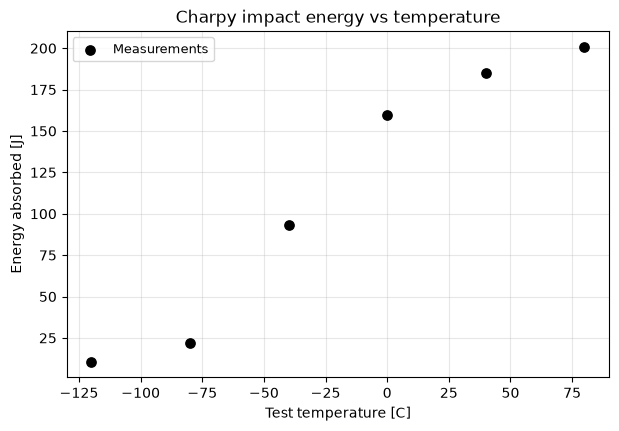

In [9]:
plot_dataset(df)
plt.show()

## 6. Add more tests

This is where the active-learning policy will eventually choose the temperatures. For
now, pick them by hand.

In [10]:
new_rows = simulator.run([-60, -50, -30, -20, -20], start_index=len(df) + 1)
df = pd.concat([df, new_rows], ignore_index=True)

print(f"{len(df)} specimens tested")
df.tail()

11 specimens tested


,Material,Condition,Processing,Orientation,NEURONE specimen ID,Test house specimen ID,Specimen Design,Specimen location,Specimen Type,Notch type,Test temperature (C),Energy absorbed (J)
6,EUROFER EAF,Base,Rolled,RD,NRN2025-0007,7,ASTM,EAF 1a Plate 1,Charpy,V notch,-60.0,28.08
7,EUROFER EAF,Base,Rolled,RD,NRN2025-0008,8,ASTM,EAF 1a Plate 1,Charpy,V notch,-50.0,68.94
8,EUROFER EAF,Base,Rolled,RD,NRN2025-0009,9,ASTM,EAF 1a Plate 1,Charpy,V notch,-30.0,113.43
9,EUROFER EAF,Base,Rolled,RD,NRN2025-0010,10,ASTM,EAF 1a Plate 1,Charpy,V notch,-20.0,145.46
10,EUROFER EAF,Base,Rolled,RD,NRN2025-0011,11,ASTM,EAF 1a Plate 1,Charpy,V notch,-20.0,149.02


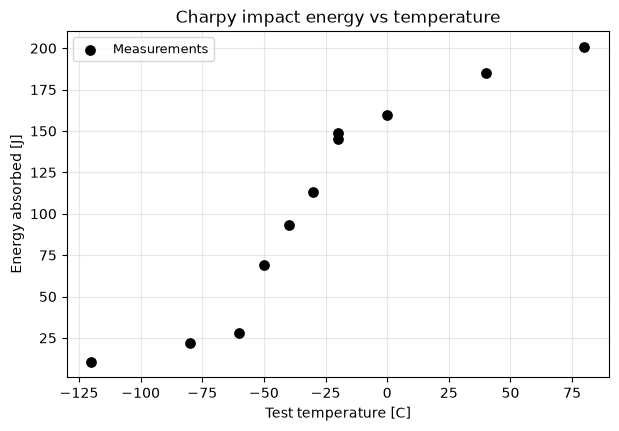

In [11]:
plot_dataset(df)
plt.show()

## 7. Save the campaign

Plain `to_csv`. Re-run this cell whenever you add tests. Note the saved table carries
only what a real test house would report — no ground-truth column.

In [12]:
DATA_PATH.parent.mkdir(parents=True, exist_ok=True)
df.to_csv(DATA_PATH, index=False)
print(f"Wrote {len(df)} rows to {DATA_PATH}")

reloaded = pd.read_csv(DATA_PATH)
reloaded.head()

Wrote 11 rows to ../data/simulated_eurofer_eaf.csv


,Material,Condition,Processing,Orientation,NEURONE specimen ID,Test house specimen ID,Specimen Design,Specimen location,Specimen Type,Notch type,Test temperature (C),Energy absorbed (J)
0,EUROFER EAF,Base,Rolled,RD,NRN2025-0001,1,ASTM,EAF 1a Plate 1,Charpy,V notch,-120.0,10.62
1,EUROFER EAF,Base,Rolled,RD,NRN2025-0002,2,ASTM,EAF 1a Plate 1,Charpy,V notch,-80.0,22.18
2,EUROFER EAF,Base,Rolled,RD,NRN2025-0003,3,ASTM,EAF 1a Plate 1,Charpy,V notch,-40.0,93.18
3,EUROFER EAF,Base,Rolled,RD,NRN2025-0004,4,ASTM,EAF 1a Plate 1,Charpy,V notch,0.0,159.83
4,EUROFER EAF,Base,Rolled,RD,NRN2025-0005,5,ASTM,EAF 1a Plate 1,Charpy,V notch,40.0,184.79


## 8. A different material

Nothing above is specific to EUROFER EAF. Point a new config at a different material and
the whole flow repeats — this is how you will test whether the active-learning policy
generalises, rather than having been tuned to one curve.

Here: a weld metal with a **higher DBTT (+20 C)**, a **lower upper shelf (120 J)**, a
sharper transition, and a noisier test house.

In [13]:
weld_config = CharpySimulatorConfig(
    name="eurofer_weld",
    seed=7,
    curve={
        "lower_shelf": 3.0,
        "upper_shelf": 120.0,
        "dbtt": 20.0,
        "width_lower": 18.0,
        "width_upper": 25.0,
    },
    noise={"base": 4.0, "relative": 0.15},
    specimen={
        "material": "EUROFER EAF",
        "condition": "Weld",
        "processing": "EB welded",
        "orientation": "TD",
        "specimen_location": "EAF 1a Plate 2",
        "neurone_id_prefix": "NRN2026-",
    },
)

weld_simulator = CharpySimulator(weld_config)
print(f"True DBTT: {weld_simulator.dbtt} C  (base material: {simulator.dbtt} C)")

True DBTT: 20.0 C  (base material: -40.0 C)


In [14]:
weld_df = pd.DataFrame(columns=COLUMNS)

for batch in ([-60, -20, 0, 20, 40, 80], [10, 30, 50]):
    rows = weld_simulator.run(batch, start_index=len(weld_df) + 1)
    weld_df = pd.concat([weld_df, rows], ignore_index=True)

WELD_PATH = Path("../data/simulated_eurofer_weld.csv")
weld_df.to_csv(WELD_PATH, index=False)

weld_df[["NEURONE specimen ID", "Material", "Condition", "Test temperature (C)", "Energy absorbed (J)"]]

,NEURONE specimen ID,Material,Condition,Test temperature (C),Energy absorbed (J)
0,NRN2026-0001,EUROFER EAF,Weld,-60.0,3.02
1,NRN2026-0002,EUROFER EAF,Weld,-20.0,5.75
2,NRN2026-0003,EUROFER EAF,Weld,0.0,12.75
3,NRN2026-0004,EUROFER EAF,Weld,20.0,49.72
4,NRN2026-0005,EUROFER EAF,Weld,40.0,91.68
5,NRN2026-0006,EUROFER EAF,Weld,80.0,97.37
6,NRN2026-0007,EUROFER EAF,Weld,10.0,32.51
7,NRN2026-0008,EUROFER EAF,Weld,30.0,105.92
8,NRN2026-0009,EUROFER EAF,Weld,50.0,100.16


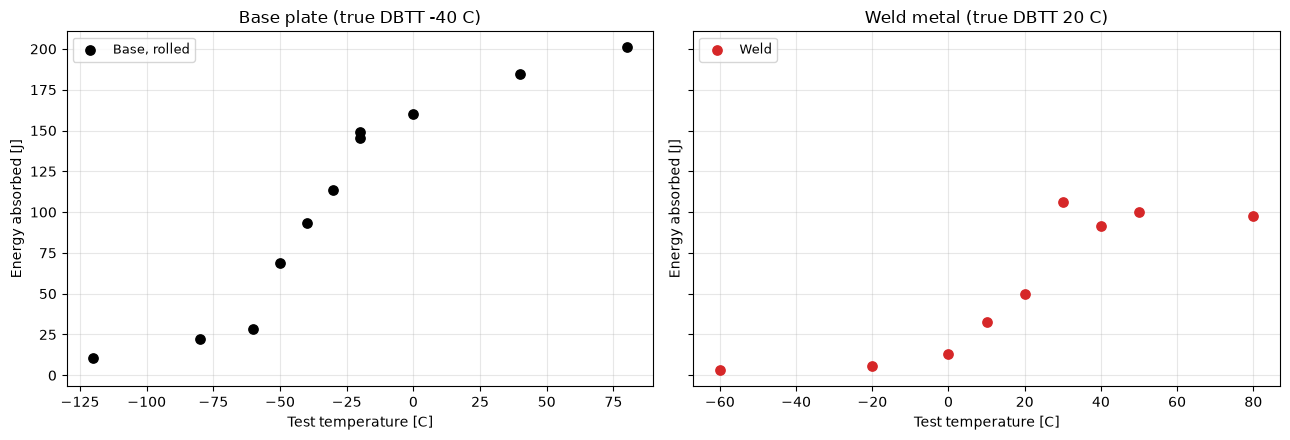

In [15]:
fig, (left, right) = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)

plot_dataset(df, ax=left, label="Base, rolled")
left.set_title(f"Base plate (true DBTT {simulator.dbtt:g} C)")

plot_dataset(weld_df, ax=right, label="Weld", color="tab:red")
right.set_title(f"Weld metal (true DBTT {weld_simulator.dbtt:g} C)")

plt.tight_layout()
plt.show()

## Next

These DataFrames are the input to the GP fit and the active-learning acquisition step:
propose the next test temperature, run it through `simulator.simulate`, `pd.concat` the
row on, refit, repeat. Scoring the loop uses `result.outputs["true_energy"]` and
`simulator.dbtt`, which are never written to the dataset.